# Cenário 2 — Remoção da variável `cibil_score`

**Dataset:** [Loan Approval Prediction Dataset](https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset) · **Algoritmo:** árvore de decisão (`DecisionTreeClassifier`) · **Tarefa:** classificação binária — prever se um pedido de empréstimo é aprovado (`Approved`) ou rejeitado (`Rejected`).

Neste cenário, **removemos a variável `cibil_score`** (score de crédito do cliente) antes de treinar o modelo, para avaliar o que a árvore consegue prever usando apenas as demais informações do pedido.

## Bibliotecas

In [1]:
# Bibliotecas para manipular os dados e desenhar gráficos
import glob
import os

import kagglehub                 # baixa datasets do Kaggle
import matplotlib.pyplot as plt
import pandas as pd

# Ferramentas do scikit-learn usadas no notebook
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier

# Semente fixa: garante que a divisão dos dados, o sorteio do undersampling
# e a árvore sejam sempre os mesmos a cada execução
RANDOM_STATE = 42

## Carregamento dos dados

In [2]:
# Baixa o dataset do Kaggle (só na primeira execução) e devolve a pasta onde ele foi salvo
path = kagglehub.dataset_download("architsharma01/loan-approval-prediction-dataset")

# Procura o arquivo .csv dentro dessa pasta e carrega numa tabela (DataFrame)
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
df = pd.read_csv(csv_path)

print("Linhas e colunas:", df.shape)
df.head()

Linhas e colunas: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
# Neste arquivo, os nomes das colunas e os textos começam com um espaço
# (ex.: " loan_status", " Approved"). Removemos esses espaços para que
# df["loan_status"] e comparações como == "Approved" funcionem.
df.columns = df.columns.str.strip()
for coluna in df.select_dtypes(exclude="number").columns:
    df[coluna] = df[coluna].str.strip()

# loan_id é apenas o número de identificação do pedido: não ajuda a prever nada
df = df.drop(columns=["loan_id"])

# Mostra o tipo de cada coluna e se há valores ausentes (Non-Null Count)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   no_of_dependents          4269 non-null   int64
 1   education                 4269 non-null   str  
 2   self_employed             4269 non-null   str  
 3   income_annum              4269 non-null   int64
 4   loan_amount               4269 non-null   int64
 5   loan_term                 4269 non-null   int64
 6   cibil_score               4269 non-null   int64
 7   residential_assets_value  4269 non-null   int64
 8   commercial_assets_value   4269 non-null   int64
 9   luxury_assets_value       4269 non-null   int64
 10  bank_asset_value          4269 non-null   int64
 11  loan_status               4269 non-null   str  
dtypes: int64(9), str(3)
memory usage: 400.3 KB


In [4]:
# Variável alvo: quantos pedidos foram aprovados e quantos foram rejeitados
print(df["loan_status"].value_counts())

# As mesmas contagens em proporção: as classes são desbalanceadas (~62% x 38%)
print()
print(df["loan_status"].value_counts(normalize=True).round(3))

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

loan_status
Approved    0.622
Rejected    0.378
Name: proportion, dtype: float64


## Cenário 2: remoção da variável `cibil_score`

Antes de remover, vemos como o score se distribui em cada classe. Quanto mais diferentes forem as faixas de score de aprovados e rejeitados, mais informação a variável carrega e mais o modelo tende a sentir sua falta.

In [5]:
# Estatísticas do cibil_score separadas por classe (média, quartis, mínimo e máximo)
df.groupby("loan_status")["cibil_score"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Approved,2656.0,703.5,125.2,300.0,618.0,711.0,803.0,900.0
Rejected,1613.0,429.5,78.4,300.0,364.0,429.0,493.0,885.0


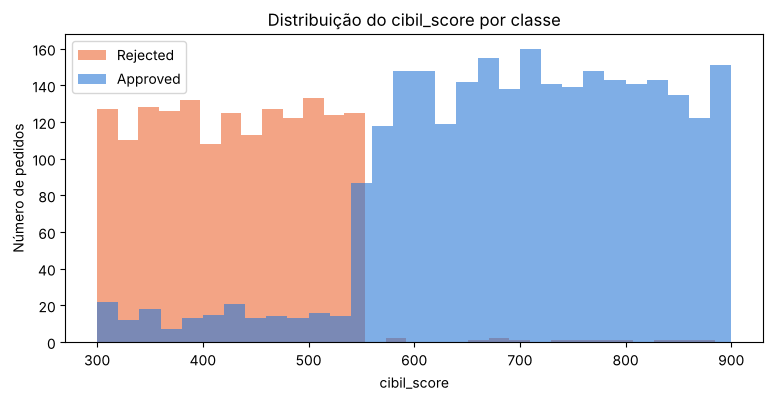

In [6]:
# Histograma do score para cada classe, sobrepostos
fig, ax = plt.subplots(figsize=(9, 4))
for classe, cor in [("Rejected", "#eb6834"), ("Approved", "#2a78d6")]:
    ax.hist(df.loc[df["loan_status"] == classe, "cibil_score"],
            bins=30, alpha=0.6, color=cor, label=classe)
ax.set_xlabel("cibil_score")
ax.set_ylabel("Número de pedidos")
ax.set_title("Distribuição do cibil_score por classe")
ax.legend()
plt.show()

In [7]:
# Remove a coluna: a partir daqui o modelo não tem acesso ao score de crédito
df = df.drop(columns=["cibil_score"])

print("Colunas restantes:", list(df.columns))

Colunas restantes: ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


## Codificação das variáveis

A árvore de decisão do scikit-learn só trabalha com números. As colunas de texto têm apenas dois valores cada, então basta trocá-las por 0 e 1.

In [8]:
# Converte as colunas de texto em 0/1
df["education"] = df["education"].map({"Graduate": 1, "Not Graduate": 0})
df["self_employed"] = df["self_employed"].map({"Yes": 1, "No": 0})

# Variável alvo: 1 = aprovado, 0 = rejeitado
df["loan_status"] = df["loan_status"].map({"Approved": 1, "Rejected": 0})

# X = variáveis de entrada (características do pedido); y = o que queremos prever
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

print("Variáveis de entrada:", list(X.columns))

Variáveis de entrada: ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


## Divisão em treino e teste

O modelo aprende com o conjunto de **treino** (80%) e é avaliado no conjunto de **teste** (20%), formado por pedidos que ele nunca viu.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,              # 20% das linhas vão para o teste
    stratify=y,                 # mantém a mesma proporção de aprovados/rejeitados nos dois conjuntos
    random_state=RANDOM_STATE,  # divisão reprodutível
)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (3415, 10) | Teste: (854, 10)


## Otimização dos hiperparâmetros com GridSearchCV

O `GridSearchCV` treina uma árvore para **cada combinação** de hiperparâmetros da grade e avalia cada uma com **validação cruzada de 5 folds**: o treino é dividido em 5 partes, e a árvore é treinada 5 vezes, cada vez deixando uma parte de fora para validação. A combinação com a melhor média é escolhida e treinada de novo com todo o conjunto de treino.

A métrica usada para escolher é o **F1 macro**: a média do F1 das duas classes. Assim, a busca valoriza árvores que acertam tanto os aprovados quanto os rejeitados, e não só a classe majoritária.

In [10]:
# Valores que serão testados para cada hiperparâmetro da árvore
param_grid = {
    "criterion": ["gini", "entropy"],        # medida de impureza usada para escolher as divisões
    "max_depth": [3, 4, 5, 6, 8, 10, 12],    # profundidade máxima (limitada para a árvore não decorar o treino)
    "min_samples_split": [2, 10, 20],        # nº mínimo de pedidos em um nó para ele poder ser dividido
    "min_samples_leaf": [1, 5, 10, 20],      # nº mínimo de pedidos em cada folha
    "class_weight": [None, "balanced"],      # "balanced" dá mais peso à classe com menos exemplos
}

# Validação cruzada estratificada: cada um dos 5 folds mantém a proporção das classes
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1_macro",   # métrica usada para comparar as combinações
    cv=cv,
    n_jobs=-1,            # usa todos os núcleos do processador para acelerar
)

# Executa a busca: treina e valida todas as combinações
grid.fit(X_train, y_train)

print("Combinações testadas:", len(grid.cv_results_["params"]))
print("Melhores hiperparâmetros:", grid.best_params_)
print("F1 macro médio na validação cruzada: %.4f" % grid.best_score_)

Combinações testadas: 336
Melhores hiperparâmetros: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 20, 'min_samples_split': 2}
F1 macro médio na validação cruzada: 0.5402


## Árvore final e previsões no teste

In [11]:
# Árvore final: a melhor combinação, já treinada com todo o conjunto de treino
melhor_arvore = grid.best_estimator_
print("Profundidade da árvore:", melhor_arvore.get_depth())
print("Número de folhas:", melhor_arvore.get_n_leaves())

# Previsões para os pedidos do conjunto de teste
y_pred = melhor_arvore.predict(X_test)

Profundidade da árvore: 12
Número de folhas: 124


## Matriz de confusão

Cada linha é a classe **real** do pedido e cada coluna, a classe **prevista** pelo modelo. A diagonal principal mostra os acertos; as outras células, os erros:

- **Rejected → Approved:** pedidos que deveriam ser rejeitados, mas o modelo aprovaria (o erro mais caro para quem empresta);
- **Approved → Rejected:** pedidos bons que o modelo rejeitaria.

À esquerda, a contagem de pedidos; à direita, a proporção dentro de cada classe real (cada linha soma 100%).

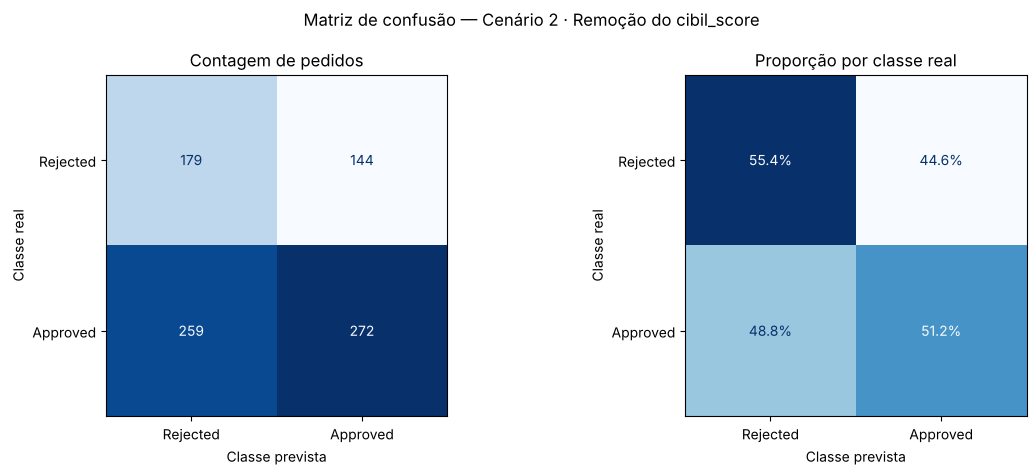

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Contagem absoluta de pedidos em cada célula
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Rejected", "Approved"],
    cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Contagem de pedidos")

# normalize="true": divide cada linha pelo total daquela classe real
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Rejected", "Approved"],
    normalize="true", values_format=".1%",
    cmap="Blues", colorbar=False, ax=axes[1],
)
axes[1].set_title("Proporção por classe real")

for ax in axes:
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
fig.suptitle("Matriz de confusão — Cenário 2 · Remoção do cibil_score")
plt.tight_layout()
plt.show()

## Classification report

Métricas calculadas no conjunto de teste, para cada classe:

- **precision:** dos pedidos que o modelo colocou nessa classe, quantos realmente eram dela;
- **recall:** dos pedidos que realmente eram dessa classe, quantos o modelo encontrou;
- **f1-score:** média harmônica entre precision e recall;
- **support:** número de pedidos de teste daquela classe.

Na parte de baixo: **accuracy** (fração total de acertos), **macro avg** (média simples das duas classes) e **weighted avg** (média ponderada pelo support).

In [13]:
print(classification_report(
    y_test, y_pred,
    target_names=["Rejected (0)", "Approved (1)"],
    digits=4,   # 4 casas decimais
))

              precision    recall  f1-score   support

Rejected (0)     0.4087    0.5542    0.4704       323
Approved (1)     0.6538    0.5122    0.5744       531

    accuracy                         0.5281       854
   macro avg     0.5313    0.5332    0.5224       854
weighted avg     0.5611    0.5281    0.5351       854

